# Figure 1D — Msn2 disorder profiles from metapredict V1, V2 and V3

Per-residue disorder scores for the *S. cerevisiae* transcription factor Msn2 (UniProt P33748) from each metapredict network. Msn2 is a long, largely disordered protein with a folded C2H2 zinc-finger DNA-binding domain near the C-terminus (shaded, residues 640–701), so a good predictor should call most of the chain disordered and dip cleanly over that domain.

**How it is made.** Scores are predicted directly with `metapredict.predict_disorder` for each network. The dashed line marks the 0.5 disorder threshold.

**Output:** `figures/figure_1D.pdf`

In [1]:
import matplotlib.pyplot as plt
import metapredict as meta
import numpy as np

from figtools import VERSION_COLORS, apply_style, require_metapredict_3_1, save_panel

apply_style()
require_metapredict_3_1()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# Msn2, UniProt P33748
msn2 = 'MTVDHDFNSEDILFPIESMSSIQYVENNNPNNINNDVIPYSLDIKNTVLDSADLNDIQNQETSLNLGLPPLSFDSPLPVTETIPSTTDNSLHLKADSNKNRDARTIENDSEIKSTNNASGSGANQYTTLTSPYPMNDILYNMNNPLQSPSPSSVPQNPTINPPINTASNETNLSPQTSNGNETLISPRAQQHTSIKDNRLSLPNGANSNLFIDTNPNNLNEKLRNQLNSDTNSYSNSISNSNSNSTGNLNSSYFNSLNIDSMLDDYVSSDLLLNDDDDDTNLSRRRFSDVITNQFPSMTNSRNSISHSLDLWNHPKINPSNRNTNLNITTNSTSSSNASPNTTTMNANADSNIAGNPKNNDATIDNELTQILNEYNMNFNDNLGTSTSGKNKSACPSSFDANAMTKINPSQQLQQQLNRVQHKQLTSSHNNSSTNMKSFNSDLYSRRQRASLPIIDDSLSYDLVNKQDEDPKNDMLPNSNLSSSQQFIKPSMILSDNASVIAKVATTGLSNDMPFLTEEGEQNANSTPNFDLSITQMNMAPLSPASSSSTSLATNHFYHHFPQQGHHTMNSKIGSSLRRRKSAVPLMGTVPLTNQQNNISSSSVNSTGNGAGVTKERRPSYRRKSMTPSRRSSVVIESTKELEEKPFHCHICPKSFKRSEHLKRHVRSVHSNERPFACHICDKKFSRSDNLSQHIKTHKKHGDI'

# annotated C2H2 zinc-finger DNA-binding domain (residues)
DBD_START, DBD_END = 640, 701
DISORDER_THRESHOLD = 0.5

metapredict 3.1.0+6.ga1b28a7.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)


In [2]:
scores = {version: meta.predict_disorder(msn2, version=version) for version in ['V1', 'V2', 'V3']}
residue = np.arange(1, len(msn2) + 1)

Wrote figures/figure_1D.pdf


PosixPath('figures/figure_1D.pdf')

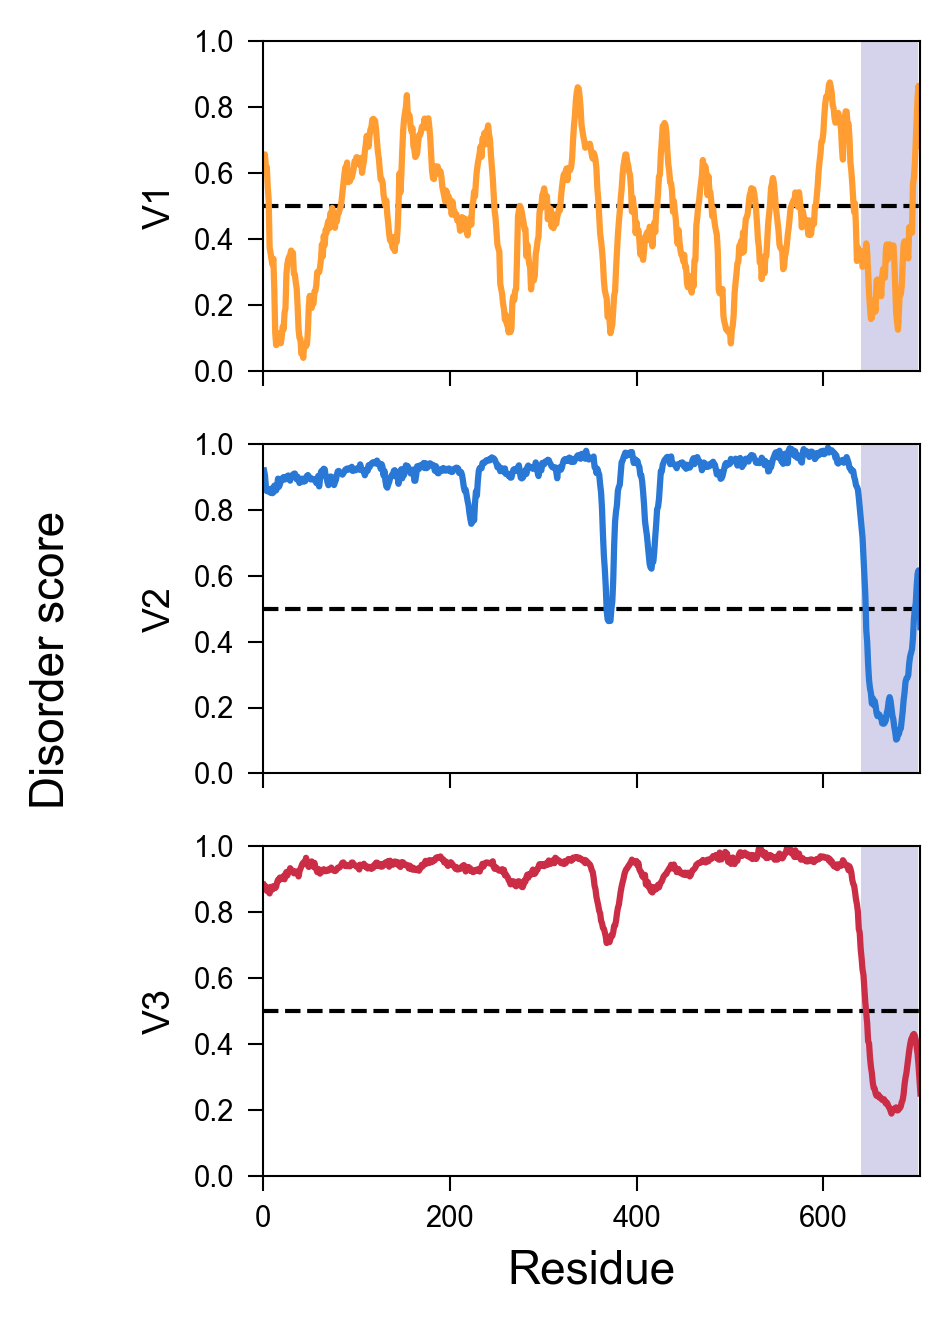

In [3]:
fig, axes = plt.subplots(nrows=3, figsize=(3.25, 4.5), dpi=150, sharex=True)
for ax, (version, disorder) in zip(axes, scores.items()):
    ax.axvspan(DBD_START, DBD_END, alpha=0.2, color='#29259d', linewidth=0, zorder=0)
    ax.axhline(DISORDER_THRESHOLD, linestyle='dashed', color='black', linewidth=1, zorder=1)
    ax.plot(residue, disorder, color=VERSION_COLORS[version], linewidth=1.5)
    ax.set_ylabel(version, fontsize=9)
    ax.set_ylim(0, 1)
    ax.set_xlim(0, len(msn2))
    ax.tick_params(labelsize=7)

axes[-1].set_xlabel('Residue', fontsize=11)
fig.supylabel('Disorder score', fontsize=11)
plt.tight_layout()
save_panel(fig, 'figure_1D')